# Online Payment Fraud, Transactional Features

Different framing from the credit-card PCA-features project. Here the features are the kind of thing a payments processor actually sees: transaction amount, hour of day, product type, card network and type, purchaser email domain, billing address, distance, and Vesta's engineered count (C) and time-delta (D) columns. No anonymized PCA components.

Data: the IEEE-CIS Fraud Detection competition data (real e-commerce transactions from Vesta Corporation, Kaggle 2019). Kaggle needs a login, so I read `train_transaction.csv` from a public Hugging Face copy (`aliceczr/ieee-fraud-detection`). The full file is 590K rows and 680MB, so I stream only the first 100,000 rows (the file is in time order, so this is roughly the first month) and skip the 339 anonymized V columns. The fraud rate in that slice is 2.6%.

Because the rows are in time order, I split by time too: the first 75% for training and the last 25% for testing, which is closer to how a fraud model is actually used.

In [1]:
import numpy as np, pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             confusion_matrix, classification_report)

OUT = Path('../../data/payment_fraud')
OUT.mkdir(parents=True, exist_ok=True)

In [2]:
PQ = OUT / 'ieee_train_first100k.parquet'
if not PQ.exists():
    url = 'https://huggingface.co/datasets/aliceczr/ieee-fraud-detection/resolve/main/train_transaction.csv'
    # stream only the first 100K rows and drop the V1-V339 columns
    pd.read_csv(url, nrows=100_000, usecols=lambda c: not c.startswith('V')).to_parquet(PQ)
raw = pd.read_parquet(PQ).sort_values('TransactionDT').reset_index(drop=True)

top_email = raw['P_emaildomain'].value_counts().index[:12]
df = pd.DataFrame({
    'amount':        raw['TransactionAmt'],
    'hour':          (raw['TransactionDT'] // 3600) % 24,      # TransactionDT is seconds from a reference time
    'product':       raw['ProductCD'],
    'card_network':  raw['card4'].fillna('missing'),
    'card_type':     raw['card6'].fillna('missing'),
    'email_domain':  raw['P_emaildomain'].where(raw['P_emaildomain'].isin(top_email), 'other').fillna('missing'),
    'addr_missing':  raw['addr1'].isna().astype(int),
    'dist1':         raw['dist1'].fillna(-1),
})
for c in [f'C{i}' for i in range(1, 15)] + ['D1', 'D4', 'D10', 'D15']:
    df[c] = raw[c].fillna(-1)
df['is_fraud'] = raw['isFraud']
print('rows', len(df), '| fraud rate', df['is_fraud'].mean().round(4))
df.head(4)

rows 100000 | fraud rate 0.0256


,amount,hour,product,card_network,card_type,email_domain,addr_missing,dist1,C1,C2,...,C10,C11,C12,C13,C14,D1,D4,D10,D15,is_fraud
0,68.5,0,W,discover,credit,other,0,19.0,1.0,1.0,...,0.0,2.0,0.0,1.0,1.0,14.0,-1.0,13.0,0.0,0
1,29.0,0,W,mastercard,credit,gmail.com,0,-1.0,1.0,1.0,...,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0
2,59.0,0,W,visa,debit,outlook.com,0,287.0,1.0,1.0,...,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,315.0,0
3,50.0,0,W,mastercard,debit,yahoo.com,0,-1.0,2.0,5.0,...,0.0,1.0,0.0,25.0,1.0,112.0,94.0,84.0,111.0,0


## Quick EDA

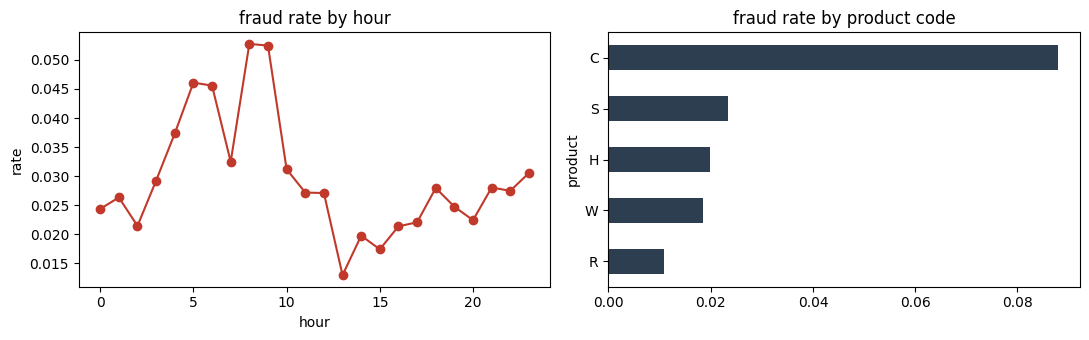

          size   mean
product              
C        11351  0.088
H        15521  0.020
R        13724  0.011
S         2526  0.023
W        56878  0.018


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df.groupby('hour')['is_fraud'].mean().plot(ax=ax[0], color='#c0392b', marker='o')
ax[0].set_title('fraud rate by hour'); ax[0].set_ylabel('rate')
df.groupby('product')['is_fraud'].mean().sort_values().plot.barh(ax=ax[1], color='#2c3e50')
ax[1].set_title('fraud rate by product code')
plt.tight_layout(); plt.show()
print(df.groupby('product')['is_fraud'].agg(['size', 'mean']).round(3))

In [4]:
# One-hot the categoricals. Tree models can use raw ordinals but keeping this simple.
feat = pd.get_dummies(df.drop(columns=['is_fraud']),
                      columns=['product', 'card_network', 'card_type', 'email_domain'], drop_first=True).astype(float)
X = feat.values
y = df['is_fraud'].values

# time-based split: rows are sorted by TransactionDT
cut = int(len(df) * 0.75)
X_tr, X_te, y_tr, y_te = X[:cut], X[cut:], y[:cut], y[cut:]
print('train', X_tr.shape, 'pos', y_tr.sum(), '| test', X_te.shape, 'pos', y_te.sum())

train (75000, 46) pos 2022 | test (25000, 46) pos 539


In [5]:
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                            class_weight='balanced', n_jobs=2, random_state=42)
rf.fit(X_tr, y_tr)
proba = rf.predict_proba(X_te)[:, 1]
print(f'ROC-AUC  {roc_auc_score(y_te, proba):.4f}')
print(f'PR-AUC   {average_precision_score(y_te, proba):.4f}')

ROC-AUC  0.8770
PR-AUC   0.4161


In [6]:
# threshold sweep -- the operating point matters more than a single F1 number
rows = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    rows.append({'thresh': t, 'tp': tp, 'fp': fp, 'fn': fn,
                 'precision': tp / max(tp + fp, 1),
                 'recall':    tp / max(tp + fn, 1)})
pd.DataFrame(rows)

,thresh,tp,fp,fn,precision,recall
0,0.2,406,3384,133,0.107124,0.753247
1,0.3,352,1839,187,0.160657,0.653061
2,0.4,322,1016,217,0.240658,0.597403
3,0.5,282,578,257,0.327907,0.523191
4,0.6,221,291,318,0.431641,0.410019
5,0.7,173,92,366,0.652830,0.320965


In [7]:
# Top-10 feature importance
imp = pd.Series(rf.feature_importances_, index=feat.columns).sort_values(ascending=False).head(10)
imp

amount    0.081873
C13       0.066354
C5        0.054527
D1        0.054523
D15       0.052719
C2        0.050587
D10       0.050291
hour      0.049108
C14       0.044553
C1        0.044299
dtype: float64

## Takeaways

- On the last 25,000 transactions (539 frauds, 2.2%), the class-weighted random forest gets ROC-AUC 0.877 and PR-AUC 0.416, trained only on the earlier 75,000. That's a lot weaker than the credit-card PCA notebook (080), which fits what I'd expect: this is a harder, more realistic setup with a time-based split and messier features.
- Product code C stands out in the EDA, with a fraud rate of 8.8% versus 1-2% for the other product codes.
- Amount is the top feature, followed by Vesta's count features (C13, C5, C2, C14, C1) and the time-delta features (D1, D15, D10), with hour of day close behind. The C and D columns are anonymized, so I can't say exactly what they count, but Vesta's competition notes describe them as counts (e.g. addresses linked to the card) and days between transactions, which are basically velocity features.
- The threshold sweep is the table that matters operationally. At t=0.5 the model catches 52% of fraud at 33% precision. Dropping to 0.3 catches 65% but with 1,839 false alarms per 25K transactions. The right value depends on how many alerts the review team can work.
- Next pass: bring back the V columns and the identity table, add per-card aggregates (card1 + addr1 as a pseudo-user ID is the well-known trick from this competition), and try gradient boosting, which did most of the winning on this data.